# 5. Methylation versus expression

*Page 5 of 8.* [previous: 4. Explainability](https://robinson-vidva.github.io/mb-methylation-xai/04_explainability.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 6. Pathways and therapy](https://robinson-vidva.github.io/mb-methylation-xai/06_pathways_and_therapy.html)

This page is what the matched expression data makes possible. A CpG can be highly discriminative
without doing anything. If promoter methylation at the model's top sites changes expression of the
gene, the explanation has biological content.

**Method.** For every gene, promoter methylation is the mean beta over its promoter probes (TSS200,
TSS1500, 5'UTR, first exon). The Spearman correlation (rho) between promoter methylation and expression
across all 763 tumours is computed for every gene with both measurements. A negative rho means that
more methylation goes with less expression, the expected direction for a promoter. The distribution
over all genes is the background. The genes under the model's top promoter CpGs are compared with it.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
TAB = Path('../results/tables')
FIG = Path('../results/figures')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)

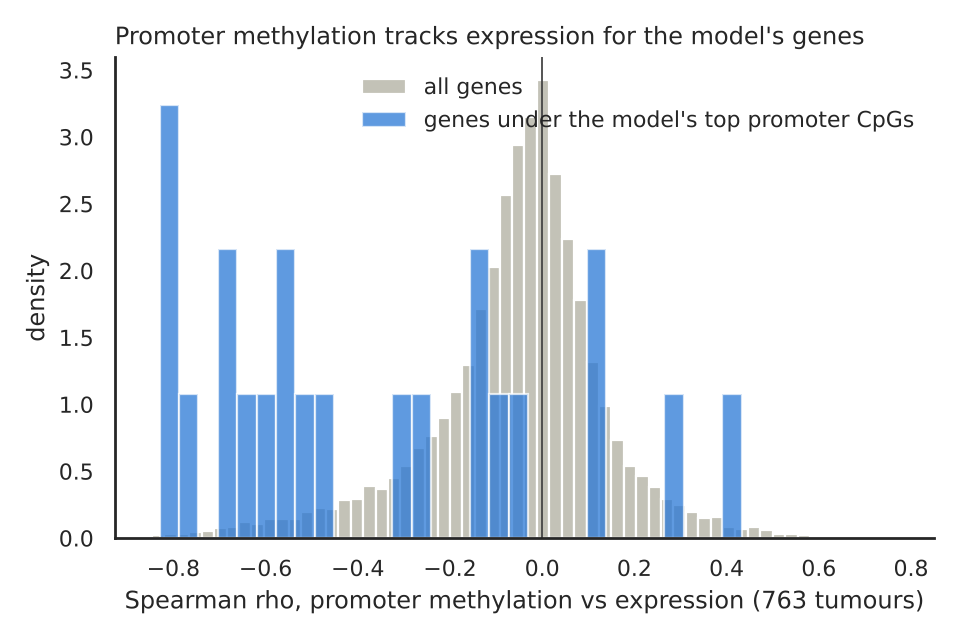

{'n_genes_tested': 15333,
 'all_genes_median_rho': -0.032803856113549586,
 'all_genes_fraction_rho_below_-0.3': 0.09606730581099589,
 'top_genes_n': 85,
 'top_genes_median_rho': -0.07452332604156746,
 'top_promoter_genes_n': 22,
 'top_promoter_genes_median_rho': -0.4857681297330989,
 'top_promoter_genes_fraction_rho_below_-0.3': 0.5909090909090909,
 'concordant_genes_per_group': {'Group3': 63,
  'Group4': 78,
  'SHH': 129,
  'WNT': 165},
 'enriched_terms_per_group': {'Group3': 46, 'SHH': 1, 'WNT': 1},
 'drivers_in_top50': 0,
 'drivers_differentially_expressed_fdr05': 20}

In [2]:
display(Image(FIG / 'methylation_vs_expression_rho.png'))
json.load(open(TAB / 'integration_summary.json'))

In [3]:
top = pd.read_csv(TAB / 'top_cpgs_with_expression_correlation.csv')
top[top['promoter_cpg']].drop_duplicates('gene').sort_values('spearman_rho')[['group', 'gene', 'cpg', 'region', 'direction', 'spearman_rho']].head(15)

,group,gene,cpg,region,direction,spearman_rho
10,WNT,VRK2,cg18998670,TSS200,hypomethylated,-0.8299
72,Group4,RBM24,cg23146346,TSS200,hypomethylated,-0.8237
79,Group4,POU2F1,cg22788908,5'UTR,hypomethylated,-0.7900
87,Group4,SLAIN1,cg21978892,5'UTR,hypomethylated,-0.7537
37,SHH,CSNK1G1,cg03840511,TSS1500,hypermethylated,-0.6946
78,Group4,LMX1A,cg23971170,TSS1500,hypomethylated,-0.6687
53,Group3,AIPL1,cg26500080,TSS200,hypomethylated,-0.6317
2,WNT,SLC20A2,cg22855020,5'UTR,hypomethylated,-0.6093
44,SHH,LRIT2,cg02790260,TSS1500,hypermethylated,-0.5600
93,Group4,PCDH9,cg27422141,5'UTR,hypermethylated,-0.5522


Across all genes the correlation is centred near zero: for most genes, promoter methylation on this
array does not track expression. For the genes under the model's top promoter CpGs it is clearly
negative, with most below -0.3. The sites the classifier relies on are, disproportionately, sites
where methylation does control expression. Examples with strong anti-correlation include VRK2 (WNT),
RBM24 and POU2F1 (Group 4) and AIPL1 (Group 3).

## Differential analysis per subgroup

The next step asks the same question subgroup by subgroup, for all genes rather than only the model's.
For each subgroup against the rest, a Mann-Whitney test is run on promoter methylation and on
expression for every gene. P-values are corrected for multiple testing with the Benjamini-Hochberg
false discovery rate (**FDR**); a gene with FDR below 0.05 is called significant. A gene is called
**concordant** when both tests are significant, the change in beta is above 0.10, the change in log2
expression is above 1 (a two-fold change), and the two changes point in opposite directions: promoter
hypomethylated with expression up, or promoter hypermethylated with expression down.

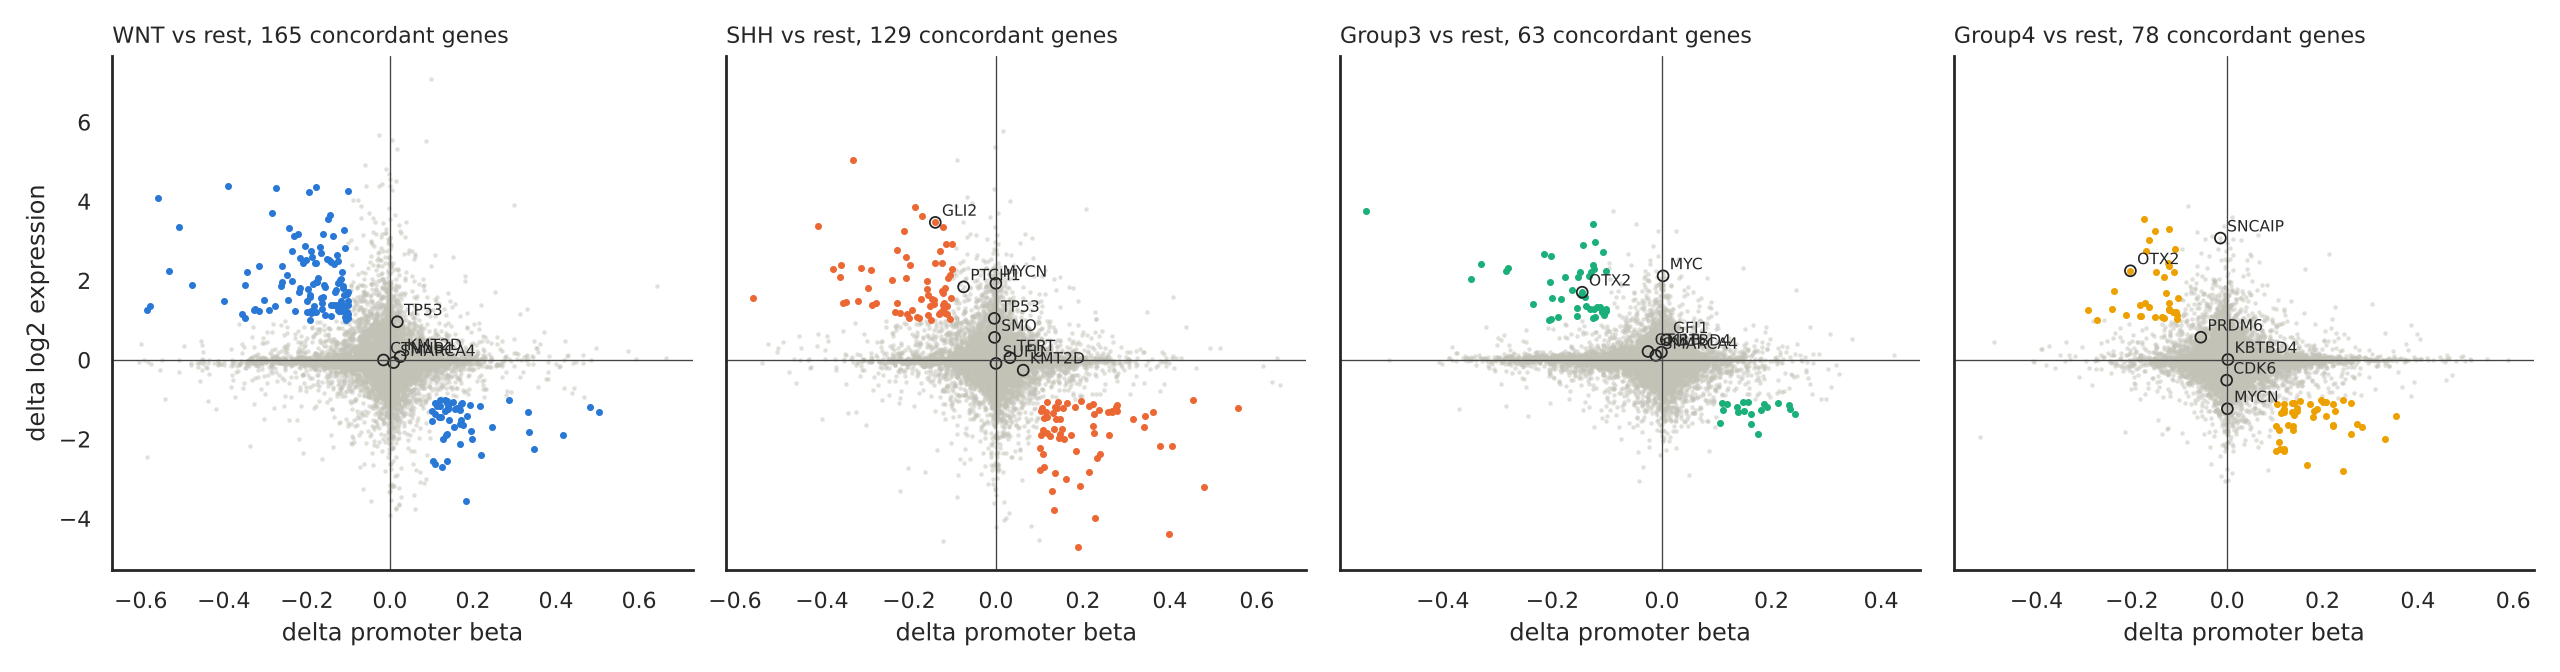

direction,"hypermethylated, expression down","hypomethylated, expression up",All
group,,,
Group3,19,44,63
Group4,44,34,78
SHH,64,65,129
WNT,51,114,165
All,178,257,435


In [4]:
display(Image(FIG / 'differential_meth_vs_expr.png'))
conc = pd.read_csv(TAB / 'concordant_genes_per_group.csv')
conc['direction'] = conc['meth_delta'].lt(0).map({True: 'hypomethylated, expression up', False: 'hypermethylated, expression down'})
pd.crosstab(conc['group'], conc['direction'], margins=True)

Each subgroup has tens to a few hundred concordant genes. Driver genes are circled in the figure.
GLI2 in SHH and OTX2 in Group 3 and Group 4 are concordant: their promoter is hypomethylated and they
are strongly expressed in their subgroup. Most other drivers are strongly over-expressed without a
promoter methylation change, which again says that drivers are switched by mutation or copy number,
not by methylation. The concordant genes are the input to the pathway and therapy page.

*Page 5 of 8.* [previous: 4. Explainability](https://robinson-vidva.github.io/mb-methylation-xai/04_explainability.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 6. Pathways and therapy](https://robinson-vidva.github.io/mb-methylation-xai/06_pathways_and_therapy.html)